# Projet 2 — Estimation du Prix de l'Immobilier

**Type :** Régression  
**Dataset :** California Housing  
**Objectif :** Prédire la valeur médiane des logements (`MedHouseVal`) à partir de 8 features socio-économiques et géographiques.

---

## Pipeline suivi
1. Chargement  
2. Exploration  
3. Nettoyage : NaN → Doublons → Outliers  
4. Transformations (encodage)  
5. Normalisation  
6. Division Train / Test  
7. Modèle MLP PyTorch  
8. Évaluation & Visualisation

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

---
## 1. Chargement des données

In [23]:
df = pd.read_csv('california_housing.csv')
print(f"Taille du dataset : {df.shape}")
df.head()

Taille du dataset : (20642, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


---
## 2. Exploration des données
On examine les types, les statistiques de base et la distribution de la variable cible.

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20642 entries, 0 to 20641
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20641 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20642 non-null  float64
 3   AveBedrms    20642 non-null  float64
 4   Population   20641 non-null  float64
 5   AveOccup     20641 non-null  float64
 6   Latitude     20641 non-null  float64
 7   Longitude    20641 non-null  float64
 8   MedHouseVal  20642 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [25]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20641.000000,20640.000000,20642.000000,20642.000000,20641.000000,20641.000000,20641.000000,20641.000000,20642.000000
mean,3.870682,28.640746,5.428920,1.096668,1425.459861,3.070674,35.631966,-119.569832,2.068553
std,1.899768,12.586691,2.474068,0.473889,1132.442718,10.385797,2.135953,2.003567,1.153924
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563700,18.000000,4.440652,1.006067,787.000000,2.429787,33.930000,-121.800000,1.196000
50%,3.534900,29.000000,5.228973,1.048780,1166.000000,2.818182,34.260000,-118.490000,1.797000
75%,4.743100,37.000000,6.052319,1.099520,1725.000000,3.282258,37.710000,-118.010000,2.647750
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


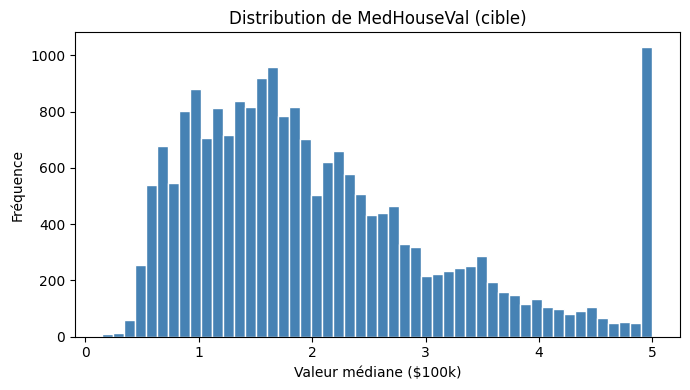

In [26]:
# Distribution de la variable cible
plt.figure(figsize=(7, 4))
plt.hist(df['MedHouseVal'], bins=50, color='steelblue', edgecolor='white')
plt.title('Distribution de MedHouseVal (cible)')
plt.xlabel('Valeur médiane ($100k)')
plt.ylabel('Fréquence')
plt.tight_layout()
plt.show()

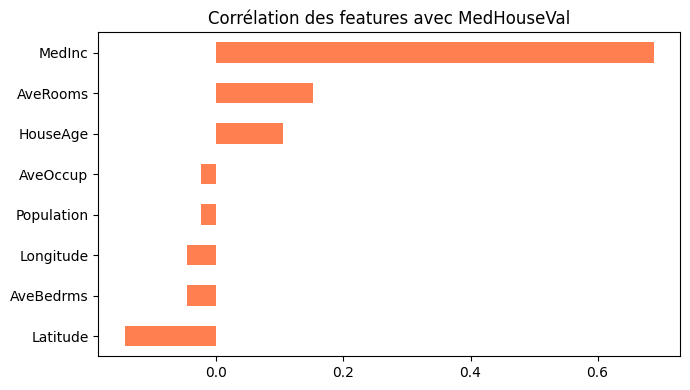

In [27]:
# Corrélation de chaque feature avec la cible
correlations = df.corr()['MedHouseVal'].drop('MedHouseVal').sort_values()

plt.figure(figsize=(7, 4))
correlations.plot(kind='barh', color='coral')
plt.title('Corrélation des features avec MedHouseVal')
plt.tight_layout()
plt.show()

---
## 3. Nettoyage des données
### 3.1 Valeurs manquantes (NaN)

In [28]:
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())

Valeurs manquantes par colonne :
MedInc         1
HouseAge       2
AveRooms       0
AveBedrms      0
Population     1
AveOccup       1
Latitude       1
Longitude      1
MedHouseVal    0
dtype: int64


In [29]:
# Remplacement des NaN par la médiane de chaque colonne
# La médiane est plus robuste que la moyenne face aux valeurs extrêmes
for col in df.columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print(f"NaN restants : {df.isnull().sum().sum()}")

NaN restants : 0


### 3.2 Doublons

In [30]:
nb_doublons = df.duplicated().sum()
print(f"Nombre de doublons : {nb_doublons}")

if nb_doublons > 0:
    df = df.drop_duplicates()
    print(f"Doublons supprimés. Nouvelle taille : {df.shape}")

Nombre de doublons : 2
Doublons supprimés. Nouvelle taille : (20640, 9)


### 3.3 Outliers
On utilise la méthode **IQR** (Interquartile Range).  
On considère comme outlier toute valeur en dehors de `[Q1 − 3×IQR, Q3 + 3×IQR]`.  
On utilise un facteur de **3** (au lieu de 1.5) pour être moins agressif et garder plus de données.

In [31]:
features = [c for c in df.columns if c != 'MedHouseVal']

# Construire un masque : True = ligne à garder
mask = pd.Series([True] * len(df), index=df.index)

for col in features:
    Q1  = df[col].quantile(0.25)
    Q3  = df[col].quantile(0.75)
    IQR = Q3 - Q1
    mask = mask & (df[col] >= Q1 - 3 * IQR) & (df[col] <= Q3 + 3 * IQR)

avant = len(df)
df = df[mask].reset_index(drop=True)
print(f"Lignes supprimées (outliers) : {avant - len(df)}")
print(f"Taille après nettoyage       : {df.shape}")

Lignes supprimées (outliers) : 1377
Taille après nettoyage       : (19263, 9)


---
## 4. Transformations — Encodage

> **Ce dataset contient uniquement des colonnes numériques** (`float64`).  
> Il n'y a **pas de variables catégorielles**, donc **aucun Label Encoding ni One-Hot Encoding n'est nécessaire** ici.

In [32]:
# Vérification : toutes les colonnes sont numériques
print(df.dtypes)

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object


---
## 5. Séparation Features / Cible

In [33]:
X = df.drop(columns=['MedHouseVal']).values  # Features (8 colonnes)
y = df['MedHouseVal'].values                 # Cible

print(f"X : {X.shape}  |  y : {y.shape}")

X : (19263, 8)  |  y : (19263,)


---
## 6. Division Train / Test  puis  Normalisation

> **Ordre important :** on divise **d'abord**, puis on applique le `StandardScaler`  
> uniquement sur le **train set** (`fit_transform`).  
> Le test set reçoit seulement un `transform` — sans regarder ses données — pour éviter le **data leakage**.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Train : {X_train.shape}  |  Test : {X_test.shape}")

Train : (15410, 8)  |  Test : (3853, 8)


In [35]:
# Fit sur le train uniquement, transform sur train ET test
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

In [36]:
# Conversion en tenseurs PyTorch (float32)
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t  = torch.tensor(X_test,  dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)  # (N,) → (N,1)
y_test_t  = torch.tensor(y_test,  dtype=torch.float32).unsqueeze(1)

# --- Mini-batch DataLoader ---
# À chaque époque on met à jour les poids après chaque bloc de BATCH_SIZE exemples
BATCH_SIZE = 64

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

print(f"Exemples train   : {len(train_dataset)}")
print(f"Batches / époque : {len(train_loader)}")

Exemples train   : 15410
Batches / époque : 241


---
## 7. Modèle MLP PyTorch

### Architecture
| Couche | Entrée → Sortie | Activation |
|--------|-----------------|------------|
| FC 1   | 8 → 128         | ReLU       |
| FC 2   | 128 → 64        | ReLU       |
| FC 3   | 64 → 32         | ReLU       |
| FC 4   | 32 → 1          | —          |

- **BatchNorm1d** après chaque couche cachée → stabilise l'apprentissage  
- **Dropout(0.2)** → régularisation contre l'overfitting  
- Pas d'activation en sortie (problème de **régression**)

In [ ]:
class MLP(nn.Module):
    def __init__(self, input_size):
        super(MLP, self).__init__()
        self.model = nn.Sequential(
            # Couche 1
            nn.Linear(input_size, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            # Couche 2
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            # Couche 3
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            # Sortie (1 neurone, pas d'activation → régression)
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.model(x)


model = MLP(input_size=X_train_t.shape[1])
print(model)

MLP(
  (model): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Linear(in_features=32, out_features=1, bias=True)
  )
)


---
## 8. Entraînement — Mini-batch Gradient Descent

### Paramètres
| Élément            | Valeur                  | Rôle |
|--------------------|-------------------------|------|
| **Batch size**     | 64                      | Taille de chaque mini-batch |
| **Loss**           | `MSELoss`               | Mesure l'erreur de régression |
| **Optimiseur**     | `Adam` (lr=0.001)       | Met à jour les poids |
| **Scheduler**      | `ReduceLROnPlateau`     | Réduit le LR si la validation stagne |
| **Early stopping** | patience = 20 époques   | Stoppe si plus d'amélioration |

> À chaque époque, on itère sur tous les mini-batches (≈ 241 batches de 64).  
> Le gradient et la mise à jour des poids se font **batch par batch**, pas sur tout le dataset d'un coup.

In [ ]:
# --- Hyperparamètres ---
EPOCHS   = 300
LR       = 1e-3
PATIENCE = 20

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=10
)

# --- Historique ---
train_losses = []
test_losses  = []

# --- Early stopping ---
best_loss    = float('inf')
patience_cnt = 0
best_weights = None

# --- Boucle d'entraînement (mini-batch) ---
for epoch in range(1, EPOCHS + 1):

    # Mode entraînement : on parcourt les mini-batches
    model.train()
    batch_losses = []
    for X_batch, y_batch in train_loader:
        pred_batch = model(X_batch)
        loss_batch = criterion(pred_batch, y_batch)

        optimizer.zero_grad()
        loss_batch.backward()
        optimizer.step()

        batch_losses.append(loss_batch.item())

    # Loss train de l'époque = moyenne sur tous les batches
    loss_train_avg = sum(batch_losses) / len(batch_losses)

    # Mode évaluation sur le test complet (pas de gradient)
    model.eval()
    with torch.no_grad():
        pred_test = model(X_test_t)
        loss_test = criterion(pred_test, y_test_t)

    train_losses.append(loss_train_avg)
    test_losses.append(loss_test.item())

    # Scheduler
    scheduler.step(loss_test)

    # Early stopping
    if loss_test.item() < best_loss:
        best_loss    = loss_test.item()
        best_weights = model.state_dict().copy()
        patience_cnt = 0
    else:
        patience_cnt += 1
        if patience_cnt >= PATIENCE:
            print(f"Early stopping à l'époque {epoch}")
            break

    if epoch % 50 == 0:
        print(f"Époque {epoch:3d}  |  Loss Train : {loss_train_avg:.4f}  |  Loss Test : {loss_test.item():.4f}")

# Recharger les meilleurs poids
model.load_state_dict(best_weights)
print(f"\nMeilleure Loss Test : {best_loss:.4f}")

---
## 9. Évaluation & Visualisation

### Courbes de Loss
Une loss train qui descend mais une loss test qui remonte = **overfitting**.  
Les deux qui descendent ensemble = bon apprentissage.

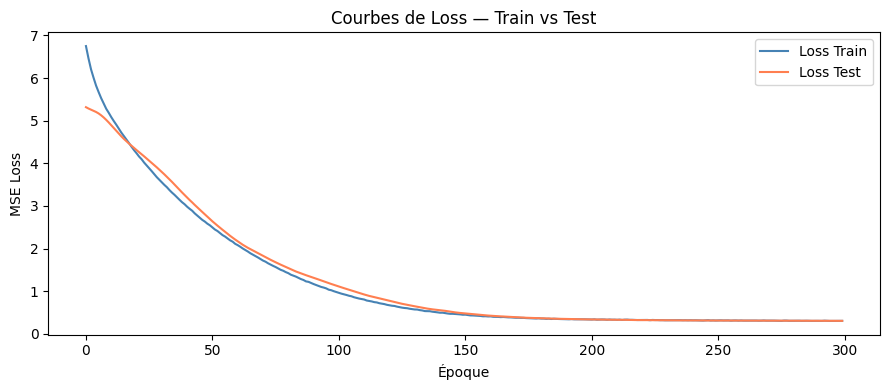

In [ ]:
plt.figure(figsize=(9, 4))
plt.plot(train_losses, label='Loss Train', color='steelblue')
plt.plot(test_losses,  label='Loss Test',  color='coral')
plt.xlabel('Époque')
plt.ylabel('MSE Loss')
plt.title('Courbes de Loss — Train vs Test')
plt.legend()
plt.tight_layout()
plt.show()

### Score R²
Le **R²** mesure la proportion de variance expliquée par le modèle.  
- R² = 1 → prédiction parfaite  
- R² = 0 → le modèle ne prédit pas mieux que la moyenne

In [ ]:
model.eval()
with torch.no_grad():
    y_pred_train = model(X_train_t).numpy()
    y_pred_test  = model(X_test_t).numpy()

r2_train = r2_score(y_train, y_pred_train)
r2_test  = r2_score(y_test,  y_pred_test)

print(f"R² Train : {r2_train:.4f}")
print(f"R² Test  : {r2_test:.4f}")

R² Train : 0.7945
R² Test  : 0.7624


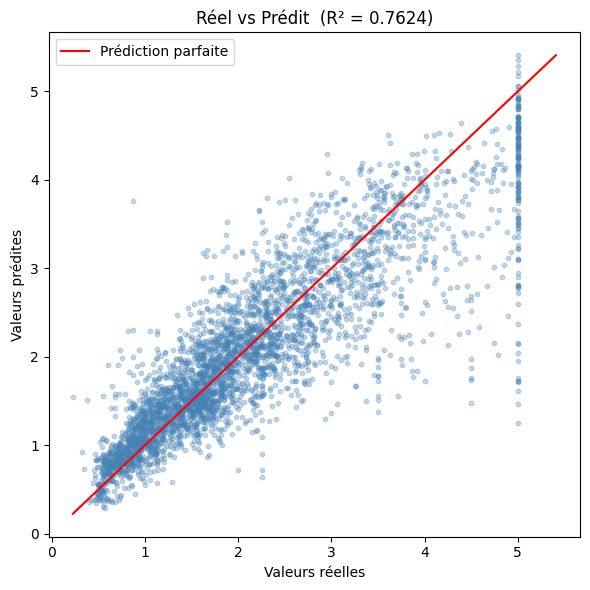

In [ ]:
# Scatter plot : valeurs réelles vs prédites
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_test, alpha=0.3, color='steelblue', s=10)

# Ligne de référence parfaite (y = x)
vmin = min(y_test.min(), y_pred_test.min())
vmax = max(y_test.max(), y_pred_test.max())
plt.plot([vmin, vmax], [vmin, vmax], color='red', linewidth=1.5, label='Prédiction parfaite')

plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title(f'Réel vs Prédit  (R² = {r2_test:.4f})')
plt.legend()
plt.tight_layout()
plt.show()

---
## 10. Sauvegarde du modèle

In [ ]:
torch.save(model.state_dict(), 'mlp_immobilier_best.pth')
print("Modèle sauvegardé : mlp_immobilier_best.pth")

Modèle sauvegardé : mlp_immobilier_best.pth
